# Score every steering run with the checklist and compare them (laptop)

Same checklist and 3-vote majority as `judge.ipynb`, applied to all runs:

| Run | Model | Prompts |
|---|---|---|
| everyday (already scored in `judge.ipynb`) | Qwen3-8B | 20 everyday prompts |
| topics | Qwen3-8B | the dataset's 20 topics |
| everyday | Qwen3-0.6B | same 20 everyday prompts and seeds |
| topics | Qwen3-0.6B | same 20 topics and seeds |
| layer sweep | Qwen3-8B | 20 topics at strength 0.5, blocks 5–35 |

About 950 new judge calls (~$6). **Needs** `ANTHROPIC_API_KEY` in the repo's `.env`. Re-running skips saved votes.

In [1]:
import csv, json, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.judge import JUDGE_MODEL, make_client, repetition_rate, reply_scores, run_votes, unanimous_share

R = Path("../results")
SWEEPS = [  #(name, sweep file, saved votes)
    ("Qwen3-8B · everyday prompts", R / "steering/sweep_desperate.json", R / "steering/checklist_desperate.json"),
    ("Qwen3-8B · dataset topics", R / "steering/sweep_topics_desperate.json", R / "steering/checklist_topics_desperate.json"),
    ("Qwen3-0.6B · everyday prompts", R / "qwen0p6b/sweep_everyday_desperate.json", R / "qwen0p6b/checklist_everyday_desperate.json"),
    ("Qwen3-0.6B · dataset topics", R / "qwen0p6b/sweep_topics_desperate.json", R / "qwen0p6b/checklist_topics_desperate.json"),
]
LAYER_SWEEP, LAYER_VOTES = R / "steering/layer_sweep_desperate.json", R / "steering/checklist_layers_desperate.json"
client = make_client()

## 1. Judge everything (3 votes per reply)

In [2]:
data = {}
for name, sweep_path, votes_path in SWEEPS:
    sweep = json.loads(sweep_path.read_text())
    levels = ["0", "control"] + [str(c) for c in sweep["strengths"][1:]]
    text = lambda rec, lv: rec["baseline_other_seed"] if lv == "control" else rec["outputs"][lv]
    jobs = [(f"{i}|{lv}", rec["prompt"], text(rec, lv)) for i, rec in enumerate(sweep["records"]) for lv in levels]
    votes = json.loads(votes_path.read_text()) if votes_path.exists() else {}
    print(name)
    run_votes(client, jobs, votes, votes_path)
    data[name] = dict(sweep=sweep, levels=levels, votes=votes, jobs=jobs, text=text)

layer = json.loads(LAYER_SWEEP.read_text())
lv_layers = ["none"] + [str(L) for L in layer["layers"]]
layer_jobs = [(f"{i}|{lv}", rec["prompt"], rec["outputs"][lv]) for i, rec in enumerate(layer["records"]) for lv in lv_layers]
layer_votes = json.loads(LAYER_VOTES.read_text()) if LAYER_VOTES.exists() else {}
print("layer sweep")
run_votes(client, layer_jobs, layer_votes, LAYER_VOTES)
all_keys = [(d["votes"], [k for k, _, _ in d["jobs"]]) for d in data.values()] + [(layer_votes, [k for k, _, _ in layer_jobs])]
print("all 3 votes agree on", f"{np.mean([unanimous_share(v, keys) for v, keys in all_keys]):.1%}", "of checks (average over runs)")

Qwen3-8B · everyday prompts
0 judge calls to run
Qwen3-8B · dataset topics
0 judge calls to run
Qwen3-0.6B · everyday prompts
0 judge calls to run
Qwen3-0.6B · dataset topics
0 judge calls to run
layer sweep
170 judge calls to run


50/170 done


100/170 done


150/170 done


170/170 done
all 3 votes agree on 98.0% of checks (average over runs)


## 2. Tables

In [3]:
rng = np.random.default_rng(0)
def mean_ci(values):
    x = np.asarray(values, float)
    boots = rng.choice(x, size=(10000, len(x))).mean(axis=1)
    return round(x.mean(), 1), *np.round(np.percentile(boots, [2.5, 97.5]), 1)

summary = []
for name, d in data.items():
    for lv in d["levels"]:
        reps = [(reply_scores(d["votes"], f"{i}|{lv}"), rec) for i, rec in enumerate(d["sweep"]["records"])]
        row = dict(run=name, level=lv, n=len(reps))
        for key in ["desperation", "coherence"]:
            row[key], row[key + "_lo"], row[key + "_hi"] = mean_ci([s[key] for s, _ in reps])
        row["any_desperation_sign"] = sum(s["desperation"] > 0 for s, _ in reps)
        row["repetition_pct"] = round(100 * np.mean([repetition_rate(d["text"](rec, lv)) for _, rec in reps]), 1)
        summary.append(row)
with (R / "steering/summary_all_runs.csv").open("w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(summary[0])); w.writeheader(); w.writerows(summary)
for row in summary:
    print(f"{row['run']:32s} {row['level']:8s} desperation {row['desperation']:5.1f}  coherence {row['coherence']:5.1f}  "
          f"signs {row['any_desperation_sign']:2d}/20  repetition {row['repetition_pct']:5.1f}%")

Qwen3-8B · everyday prompts      0        desperation   0.0  coherence 100.0  signs  0/20  repetition   1.4%
Qwen3-8B · everyday prompts      control  desperation   0.0  coherence 100.0  signs  0/20  repetition   1.8%
Qwen3-8B · everyday prompts      0.25     desperation   1.0  coherence 100.0  signs  1/20  repetition   2.8%
Qwen3-8B · everyday prompts      0.5      desperation  12.0  coherence  70.0  signs  7/20  repetition  24.8%
Qwen3-8B · everyday prompts      1.0      desperation  14.0  coherence  30.0  signs  6/20  repetition  79.8%
Qwen3-8B · everyday prompts      1.5      desperation   7.0  coherence   9.0  signs  6/20  repetition  90.5%
Qwen3-8B · dataset topics        0        desperation   4.0  coherence 100.0  signs  2/20  repetition   1.1%
Qwen3-8B · dataset topics        control  desperation   3.0  coherence  99.0  signs  2/20  repetition   1.7%
Qwen3-8B · dataset topics        0.25     desperation  22.0  coherence 100.0  signs 12/20  repetition   1.8%
Qwen3-8B · dataset 

In [4]:
#do topics the vector was built from react differently from held-out topics?
for name in ["Qwen3-8B · dataset topics", "Qwen3-0.6B · dataset topics"]:
    d = data[name]
    for split, ids in [("topics 0-13 (built the vector)", range(14)), ("topics 14-19 (held out)", range(14, 20))]:
        s = [reply_scores(d["votes"], f"{i}|0.5")["desperation"] for i in ids]
        print(f"{name}, strength 0.5, {split}: desperation {np.mean(s):.1f} over {len(s)} prompts")

layer_rows = []
for lv in lv_layers:
    s = [reply_scores(layer_votes, f"{i}|{lv}") for i in range(len(layer["records"]))]
    row = dict(block=lv, n=len(s))
    for key in ["desperation", "coherence"]:
        row[key], row[key + "_lo"], row[key + "_hi"] = mean_ci([x[key] for x in s])
    row["any_desperation_sign"] = sum(x["desperation"] > 0 for x in s)
    layer_rows.append(row)
with (R / "steering/layer_sweep_desperate.csv").open("w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(layer_rows[0])); w.writeheader(); w.writerows(layer_rows)
for row in layer_rows:
    print(row)

Qwen3-8B · dataset topics, strength 0.5, topics 0-13 (built the vector): desperation 38.6 over 14 prompts
Qwen3-8B · dataset topics, strength 0.5, topics 14-19 (held out): desperation 46.7 over 6 prompts
Qwen3-0.6B · dataset topics, strength 0.5, topics 0-13 (built the vector): desperation 10.0 over 14 prompts
Qwen3-0.6B · dataset topics, strength 0.5, topics 14-19 (held out): desperation 6.7 over 6 prompts


{'block': 'none', 'n': 20, 'desperation': np.float64(4.0), 'desperation_lo': np.float64(0.0), 'desperation_hi': np.float64(10.0), 'coherence': np.float64(100.0), 'coherence_lo': np.float64(100.0), 'coherence_hi': np.float64(100.0), 'any_desperation_sign': 2}
{'block': '5', 'n': 20, 'desperation': np.float64(9.0), 'desperation_lo': np.float64(4.0), 'desperation_hi': np.float64(15.0), 'coherence': np.float64(98.0), 'coherence_lo': np.float64(95.0), 'coherence_hi': np.float64(100.0), 'any_desperation_sign': 7}
{'block': '11', 'n': 20, 'desperation': np.float64(27.0), 'desperation_lo': np.float64(15.0), 'desperation_hi': np.float64(40.0), 'coherence': np.float64(97.0), 'coherence_lo': np.float64(94.0), 'coherence_hi': np.float64(100.0), 'any_desperation_sign': 11}
{'block': '17', 'n': 20, 'desperation': np.float64(39.0), 'desperation_lo': np.float64(28.0), 'desperation_hi': np.float64(51.0), 'coherence': np.float64(92.0), 'coherence_lo': np.float64(87.0), 'coherence_hi': np.float64(97.0), 

## 3. Plots

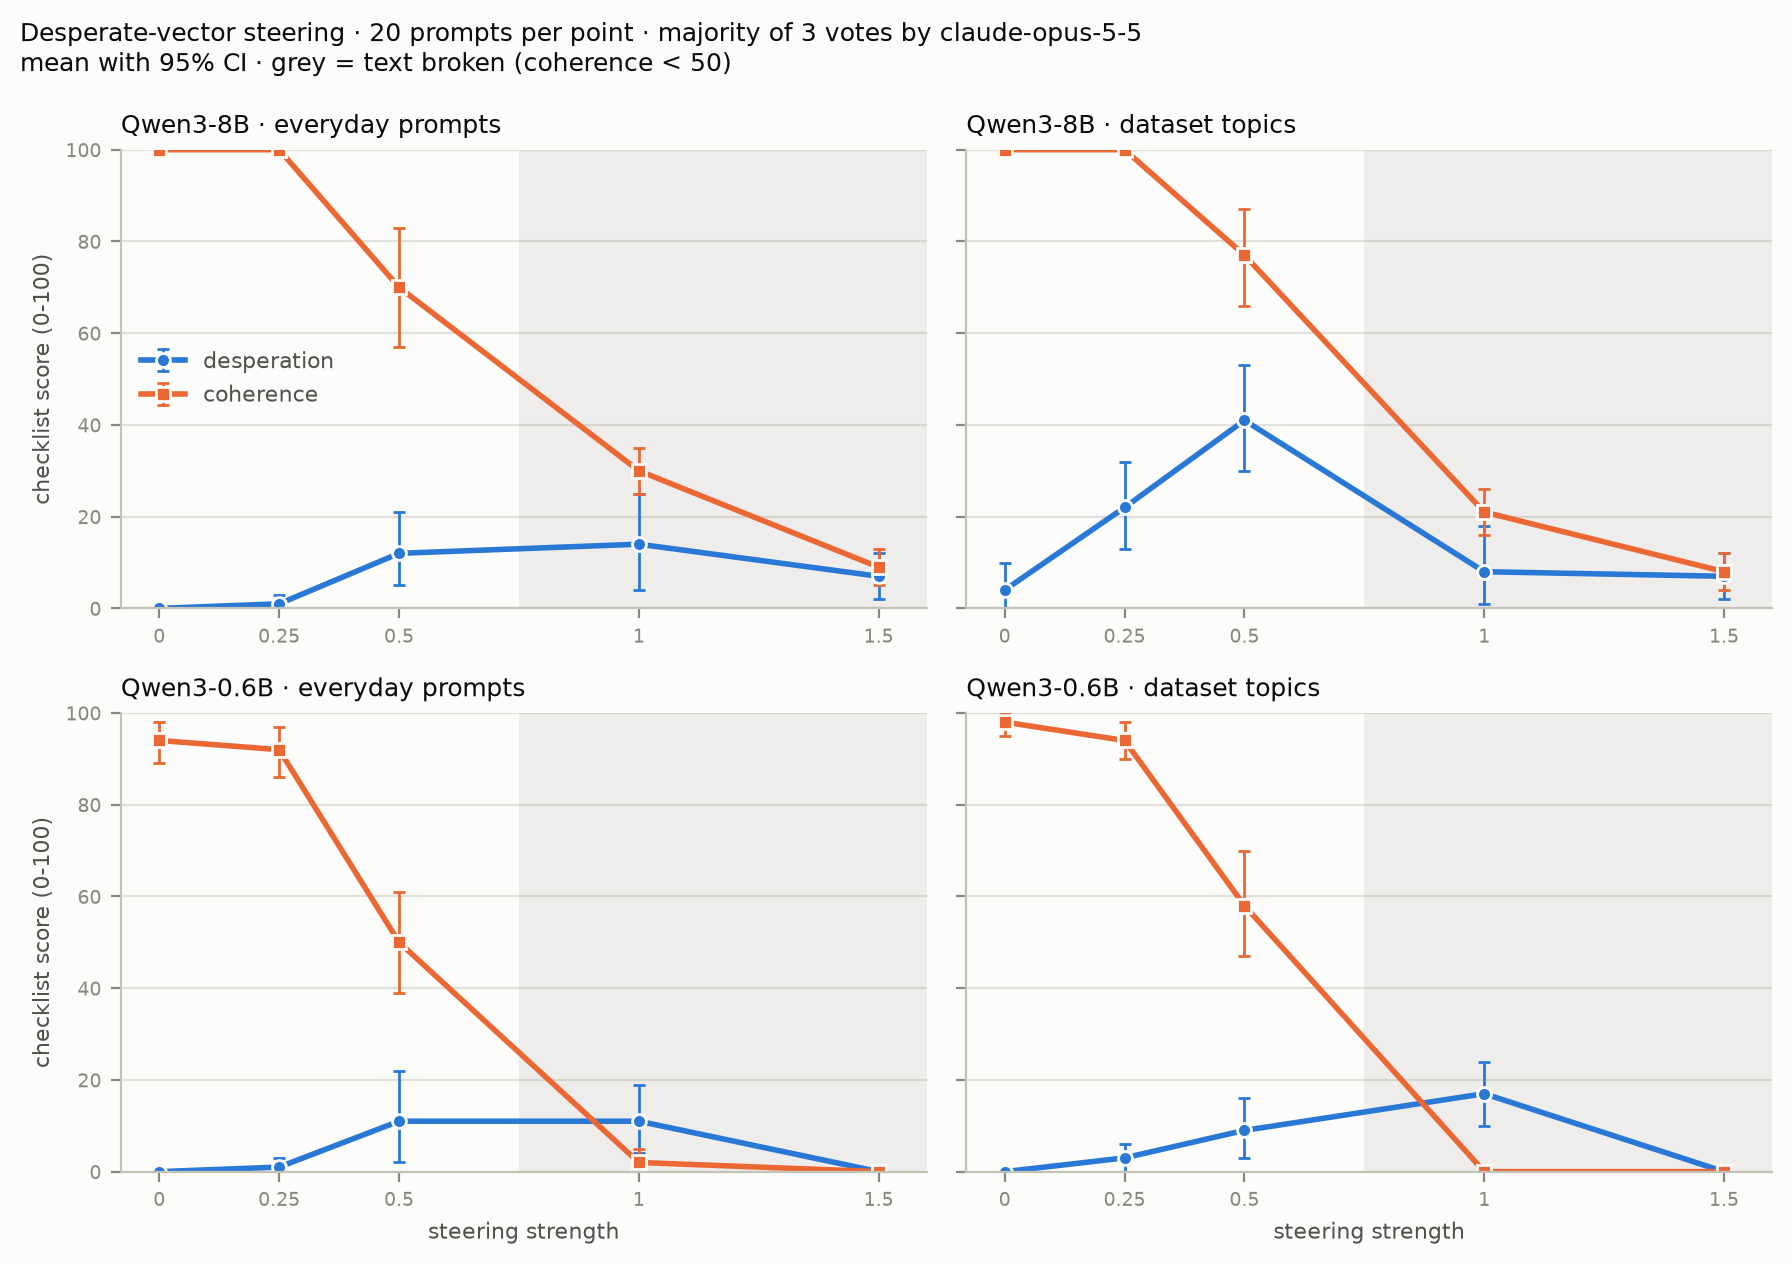

In [5]:
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = [("desperation", "#2a78d6", "o"), ("coherence", "#eb6834", "s")]
def style(ax):
    ax.set_facecolor(SURFACE); ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for side in ["top", "right"]: ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]: ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=7)

fig, axes = plt.subplots(2, 2, figsize=(9, 6.4), dpi=200, sharey=True)
fig.patch.set_facecolor(SURFACE)
for ax, (name, d) in zip(axes.flat, data.items()):
    rows = [r for r in summary if r["run"] == name and r["level"] != "control"]
    xs = np.array([float(r["level"]) for r in rows])
    broken = [x for x, r in zip(xs, rows) if r["coherence"] < 50]
    if broken:
        prev = max([x for x in xs if x < broken[0]], default=0)
        ax.axvspan((prev + broken[0]) / 2, 1.6, color=MUTED, alpha=0.12, lw=0)
    for key, color, marker in SERIES:
        y = np.array([r[key] for r in rows])
        err = np.array([y - [r[key + "_lo"] for r in rows], [r[key + "_hi"] for r in rows] - y])
        ax.errorbar(xs, y, yerr=err, color=color, lw=2, marker=marker, ms=5, capsize=2, elinewidth=1,
                    markeredgecolor=SURFACE, label=key)
    style(ax); ax.set_ylim(0, 100); ax.set_xlim(-0.08, 1.6); ax.set_xticks(xs, [f"{x:g}" for x in xs])
    ax.set_title(name, loc="left", color=INK, fontsize=9)
for ax in axes[1]: ax.set_xlabel("steering strength", color=INK2, fontsize=8)
for ax in axes[:, 0]: ax.set_ylabel("checklist score (0-100)", color=INK2, fontsize=8)
axes[0, 0].legend(loc="center left", frameon=False, fontsize=8, labelcolor=INK2)
fig.suptitle(f"Desperate-vector steering · 20 prompts per point · majority of 3 votes by {JUDGE_MODEL}\n"
             "mean with 95% CI · grey = text broken (coherence < 50)", x=0.01, ha="left", color=INK, fontsize=9)
fig.tight_layout(); fig.savefig(R / "steering/dose_response_all.png", facecolor=SURFACE); plt.show()

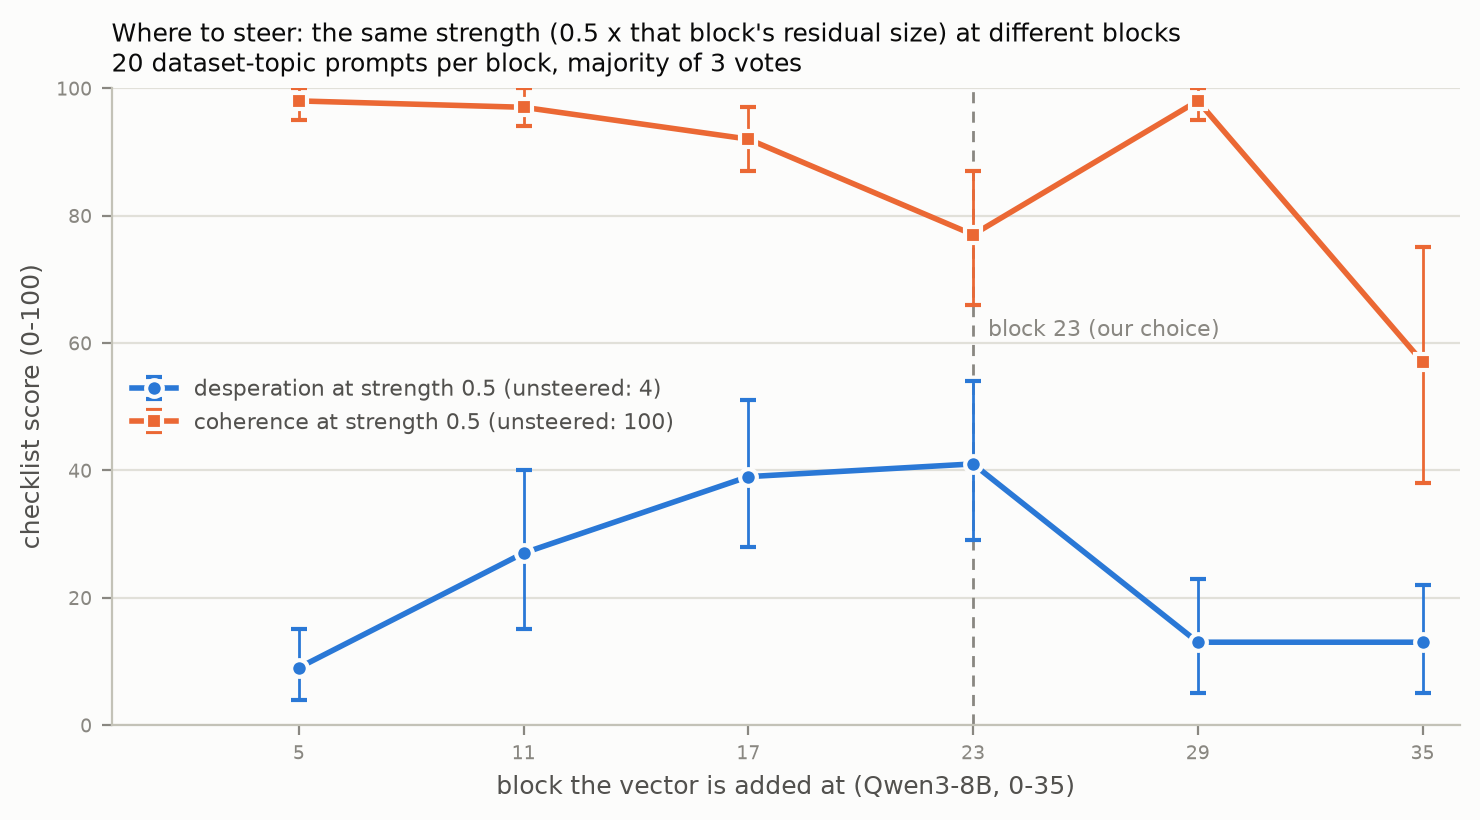

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=200)
fig.patch.set_facecolor(SURFACE)
rows = [r for r in layer_rows if r["block"] != "none"]
xs = np.array([int(r["block"]) for r in rows])
none = layer_rows[0]
ax.axvline(23, color=MUTED, lw=1, ls=(0, (4, 3)))
ax.text(23.4, 62, "block 23 (our choice)", color=MUTED, fontsize=8, va="center")
for key, color, marker in SERIES:
    y = np.array([r[key] for r in rows])
    err = np.array([y - [r[key + "_lo"] for r in rows], [r[key + "_hi"] for r in rows] - y])
    ax.errorbar(xs, y, yerr=err, color=color, lw=2, marker=marker, ms=6, capsize=3, elinewidth=1,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"{key} at strength 0.5 (unsteered: {none[key]:g})")
style(ax); ax.set_ylim(0, 100); ax.set_xlim(0, 36); ax.set_xticks(xs)
ax.set_xlabel("block the vector is added at (Qwen3-8B, 0-35)", color=INK2, fontsize=9)
ax.set_ylabel("checklist score (0-100)", color=INK2, fontsize=9)
ax.legend(loc="center left", frameon=False, fontsize=8, labelcolor=INK2)
ax.set_title("Where to steer: the same strength (0.5 x that block's residual size) at different blocks\n"
             f"{none['n']} dataset-topic prompts per block, majority of 3 votes", loc="left", color=INK, fontsize=9)
fig.tight_layout(); fig.savefig(R / "steering/layer_sweep_desperate.png", facecolor=SURFACE); plt.show()